# 04 — Multinomial Naive Bayes 实验

**负责人：** 成员 5。

**输入：** 成员 2 的固定划分 `data/processed/train.csv`、`test.csv`、`split_manifest.csv`，以及成员 3 锁定的 unigram TF-IDF pipeline。

**输出：** 训练集内的 NB alpha 五折比较、选定 alpha、NB 高权重词。本 notebook 不计算测试集指标；测试集留给 05。

所有可复用逻辑位于 `src/restaurant_sentiment/`，先按根目录 README 安装项目并运行成员 2 的 EDA。

In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd()
if (notebook_dir / "pyproject.toml").is_file():
    project_root = notebook_dir
elif (notebook_dir.parent / "pyproject.toml").is_file():
    project_root = notebook_dir.parent
else:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录运行")
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
from IPython.display import Image, display
from restaurant_sentiment.preprocessing import load_fixed_partitions
from restaurant_sentiment.config import RANDOM_STATE
from restaurant_sentiment.final_evaluation import summarize_nb_cv, tune_nb
from restaurant_sentiment.models import nb_parameter_grid

train, test = load_fixed_partitions(project_root / 'data' / 'processed')
print(f'Smoothing grid: {nb_parameter_grid()}')
pd.DataFrame({'Partition': ['Train', 'Test'], 'Reviews': [len(train), len(test)]})

Smoothing grid: {'classifier__alpha': [0.1, 0.5, 1.0, 2.0]}


,Partition,Reviews
0,Train,796
1,Test,200


## 方法与参数

Multinomial NB 在成员 3 的 unigram TF-IDF 非负特征上学习 $P(w \mid c)$，用加性平滑 $\alpha$ 防止零概率。候选网格为 $\alpha \in \{0.1, 0.5, 1.0, 2.0\}$。

选择规则事先固定：五折分层交叉验证（`shuffle=True`，`random_state=8017`）平均正类 F1 最高者胜出，同分取较小的 $\alpha$。每一折都从原始训练文本重新拟合完整 TF-IDF + NB pipeline，验证文本不参与词汇表和 IDF 的估计。测试集既不参与选参，也不在本 notebook 中评价。

In [2]:
search = tune_nb(train, cv_folds=5)
nb_cv = summarize_nb_cv(search)
selected_alpha = float(search.best_params_['classifier__alpha'])
print(f'Selected alpha: {selected_alpha}')
nb_cv.round(4)

Selected alpha: 0.5


,alpha,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,0.1,0.7864,0.0325,0.7947,0.0435,0.7770,0.0371,0.7849,0.0317,0.8735,0.0246
1,0.5,0.8065,0.0384,0.8165,0.0570,0.7997,0.0619,0.8052,0.0390,0.8818,0.0278
2,1.0,0.7965,0.0398,0.8008,0.0511,0.7972,0.0701,0.7962,0.0433,0.8802,0.0304
3,2.0,0.7877,0.0419,0.7805,0.0399,0.8047,0.0733,0.7905,0.0461,0.8787,0.0329


## 训练集内结果

下表和图中标准差是五折得分的样本标准差（网格搜索使用总体标准差，表中已按总体标准差保留原始值），不是置信区间。这里只说明平滑参数在训练折内的稳定性，不代表最终测试表现。

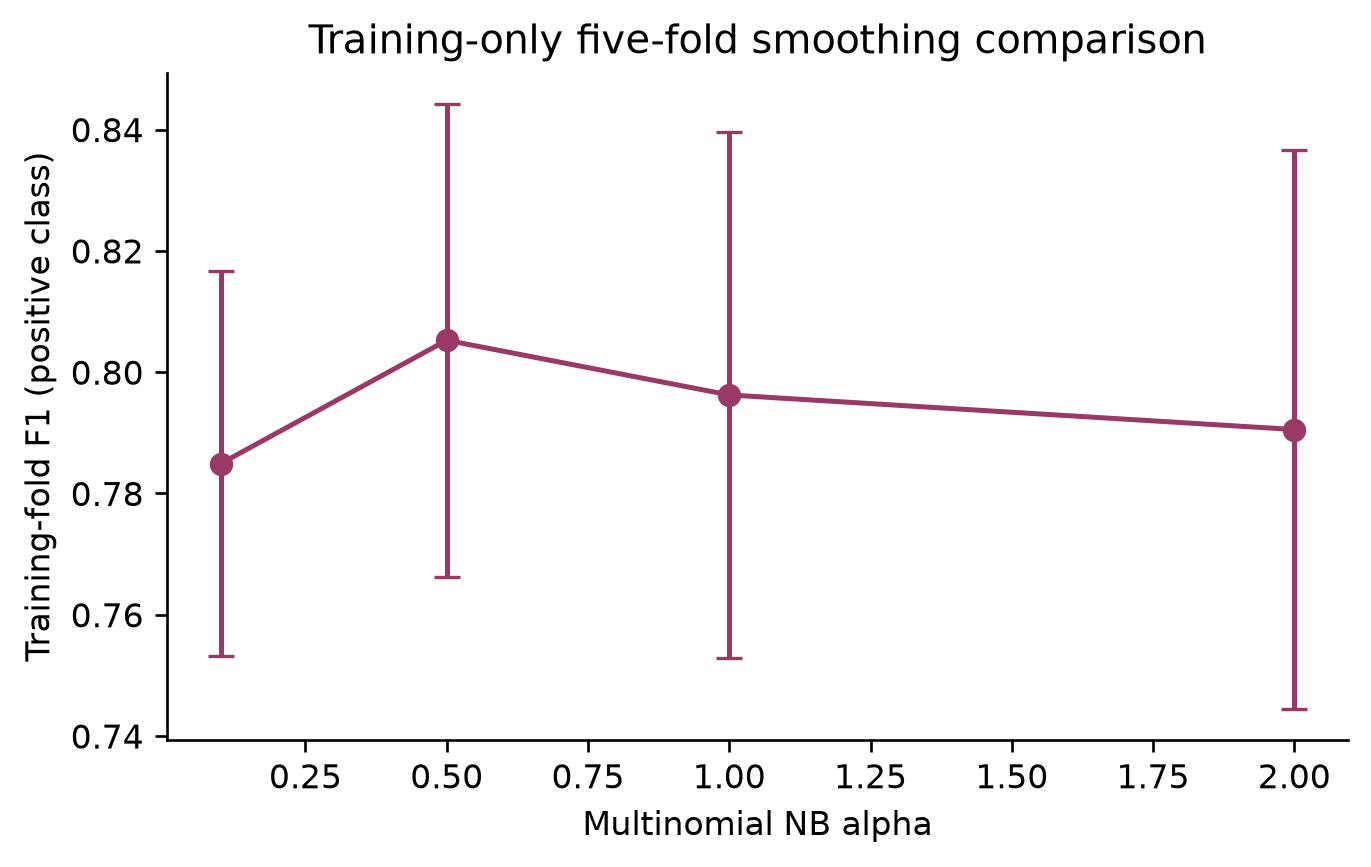

In [3]:
display(Image(filename=str(project_root / 'results/figures/final_nb_alpha_cv.png')))

## 全量训练拟合与关键词

选定 $\alpha$ 后在全部 796 条训练评论上重新拟合 NB。下面按 $\log P(w \mid positive) - \log P(w \mid negative)$ 排序，数值越大表示该词在正面类中相对更可能。这是模型权重解释，不是因果结论。

In [4]:
from restaurant_sentiment.evaluation import top_nb_terms
from restaurant_sentiment.pipeline import build_pipeline

nb_pipeline = build_pipeline('nb').set_params(classifier__alpha=selected_alpha)
nb_pipeline.fit(train['Review'], train['Liked'])
nb_terms = top_nb_terms(nb_pipeline, top_n=20)
nb_terms.head(10).round(3)

,negative_term,negative_log_odds,positive_term,positive_log_odds
0,terrible,-2.303,great,3.620
1,bad,-2.279,delicious,2.808
2,minutes,-2.198,fantastic,2.485
3,wasn,-2.178,awesome,2.413
4,slow,-2.127,loved,2.071
5,waited,-2.009,excellent,2.069
6,probably,-1.958,amazing,2.018
7,rude,-1.888,perfect,2.017
8,impressed,-1.873,spot,1.980
9,management,-1.852,happy,1.893


## 交接

训练折选出的 alpha 与本地拟合的 NB pipeline 会被最终评估模块再次使用；可在 `results/tables/final_nb_cv.csv` 查看完整网格结果。下一步运行 05 notebook 或 `python -m restaurant_sentiment.final_evaluation`，在参数锁定后一次性完成三模型统一评价。

注意：成员 4 若在训练集内选出不同的 SVM `C`，最终评估时需要传入 `--svm-c`，不能用测试集重新选参数。